# Project 12: Understanding Convolution and Pooling

## Objective
Use Python to understand how convolution and pooling operations extract important features from images.

## Tasks
1. Load a sample image.
2. Apply convolution filters and pooling operations.
3. Visualize and compare the original image and generated feature maps.

## Expected Result
Observe how convolution filters highlight features such as edges and textures, and how pooling reduces spatial dimensions while retaining prominent information.

## 1. Import Libraries

We use NumPy for numerical operations, Matplotlib for visualizations, scikit-learn's bundled sample image, and SciPy for 2D convolution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_image
from scipy.signal import convolve2d

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load a Sample Image

A sample photograph is loaded and converted to grayscale to make the 2D convolution results easier to interpret.

Image shape: (427, 640)


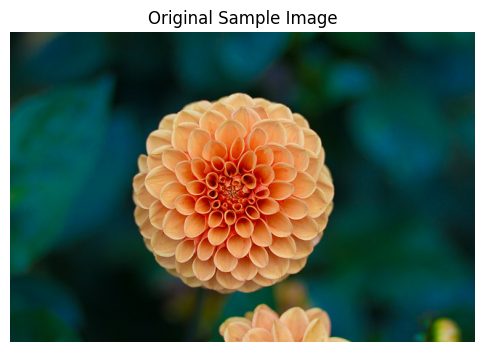

In [2]:
# Load a sample photograph bundled with scikit-learn
image_rgb = load_sample_image("flower.jpg")

# Convert RGB to grayscale, then scale pixels to [0, 1]
image_gray = (
    0.2989 * image_rgb[..., 0] +
    0.5870 * image_rgb[..., 1] +
    0.1140 * image_rgb[..., 2]
).astype(np.float32) / 255.0

print("Image shape:", image_gray.shape)

plt.figure(figsize=(6, 5))
plt.imshow(image_rgb)
plt.title("Original Sample Image")
plt.axis("off")
plt.show()

## 3. Define Convolution Filters

Convolution applies a small matrix called a **kernel** across an image. Each output value depends on the neighboring pixels and the kernel weights.

- **Identity:** preserves input intensities.
- **Edge detection:** responds to intensity changes.
- **Sharpen:** emphasizes boundaries and detail.
- **Blur:** averages nearby pixel values.

In [3]:
identity_kernel = np.array([
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 0]
], dtype=np.float32)

edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

blur_kernel = np.ones((3, 3), dtype=np.float32) / 9.0

print("Identity kernel:\n", identity_kernel)
print("\nEdge detection kernel:\n", edge_kernel)
print("\nSharpen kernel:\n", sharpen_kernel)
print("\nBlur kernel:\n", blur_kernel)

Identity kernel:
 [[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]]

Edge detection kernel:
 [[-1. -1. -1.]
 [-1.  8. -1.]
 [-1. -1. -1.]]

Sharpen kernel:
 [[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]

Blur kernel:
 [[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


## 4. Apply Convolution and Visualize Feature Maps

Convolution outputs may contain values below 0 or above 1, so results are clipped or scaled for display only.

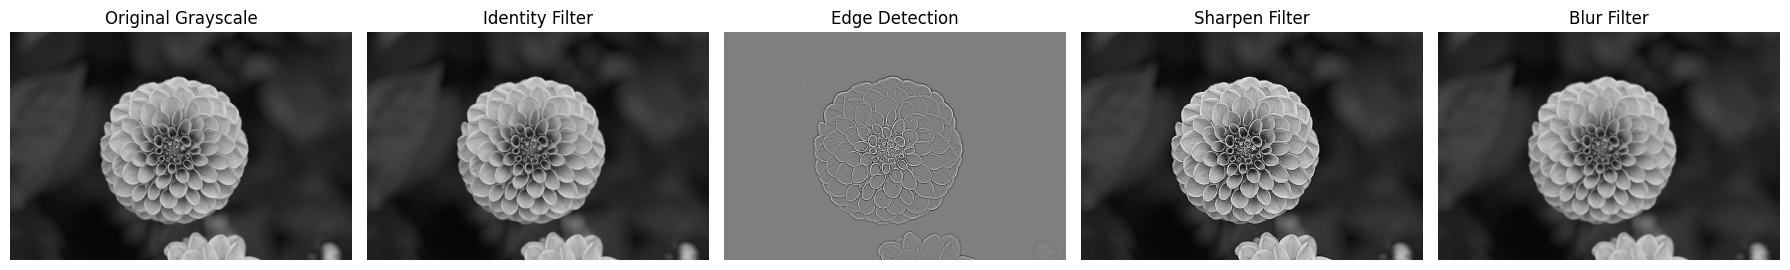

In [4]:
identity_result = convolve2d(
    image_gray, identity_kernel, mode="same", boundary="symm"
)
edge_result = convolve2d(
    image_gray, edge_kernel, mode="same", boundary="symm"
)
sharpen_result = convolve2d(
    image_gray, sharpen_kernel, mode="same", boundary="symm"
)
blur_result = convolve2d(
    image_gray, blur_kernel, mode="same", boundary="symm"
)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

axes[0].imshow(image_gray, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Grayscale")

axes[1].imshow(identity_result, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Identity Filter")

edge_limit = np.percentile(np.abs(edge_result), 99)
axes[2].imshow(edge_result, cmap="gray", vmin=-edge_limit, vmax=edge_limit)
axes[2].set_title("Edge Detection")

axes[3].imshow(sharpen_result, cmap="gray", vmin=0, vmax=1)
axes[3].set_title("Sharpen Filter")

axes[4].imshow(blur_result, cmap="gray", vmin=0, vmax=1)
axes[4].set_title("Blur Filter")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Apply Max Pooling and Average Pooling

Pooling reduces image or feature-map size.

- **Max pooling:** keeps the largest value in each local region. It can preserve strong activations such as prominent edges.
- **Average pooling:** keeps the average value in each local region. It produces a smoother representation.

We use non-overlapping **2 × 2** regions, so each spatial dimension is reduced by half.

Original shape: (427, 640)
Max-pooled shape: (213, 320)
Average-pooled shape: (213, 320)


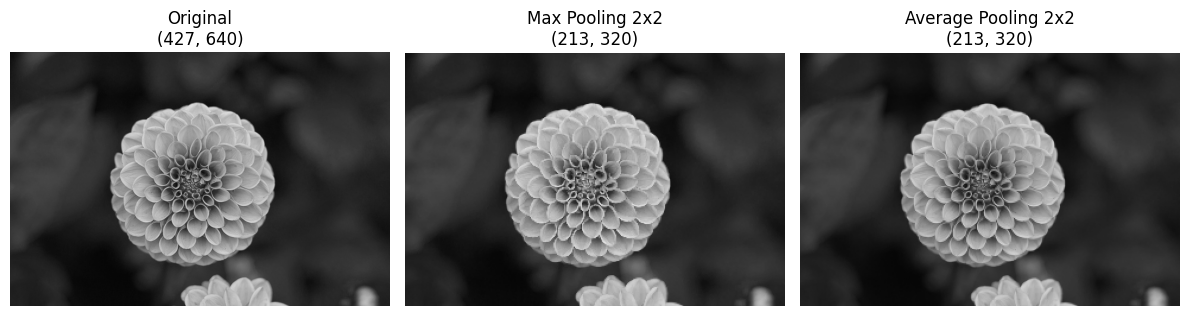

In [5]:
def pool_2x2(array, mode="max"):
    height, width = array.shape
    height -= height % 2
    width -= width % 2
    cropped = array[:height, :width]

    # Split the image into non-overlapping 2x2 blocks
    blocks = cropped.reshape(height // 2, 2, width // 2, 2)

    if mode == "max":
        return blocks.max(axis=(1, 3))
    if mode == "average":
        return blocks.mean(axis=(1, 3))
    raise ValueError("mode must be 'max' or 'average'")


max_pooled = pool_2x2(image_gray, mode="max")
avg_pooled = pool_2x2(image_gray, mode="average")

print("Original shape:", image_gray.shape)
print("Max-pooled shape:", max_pooled.shape)
print("Average-pooled shape:", avg_pooled.shape)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image_gray, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Original\n{image_gray.shape}")

axes[1].imshow(max_pooled, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Max Pooling 2x2\n{max_pooled.shape}")

axes[2].imshow(avg_pooled, cmap="gray", vmin=0, vmax=1)
axes[2].set_title(f"Average Pooling 2x2\n{avg_pooled.shape}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Pool the Edge Feature Map

A common CNN pattern is:

**Image → Convolution / Feature Extraction → Pooling / Downsampling**

The absolute edge-response map is scaled to [0, 1] and then pooled. This demonstrates how pooling retains local edge responses while reducing the map's size.

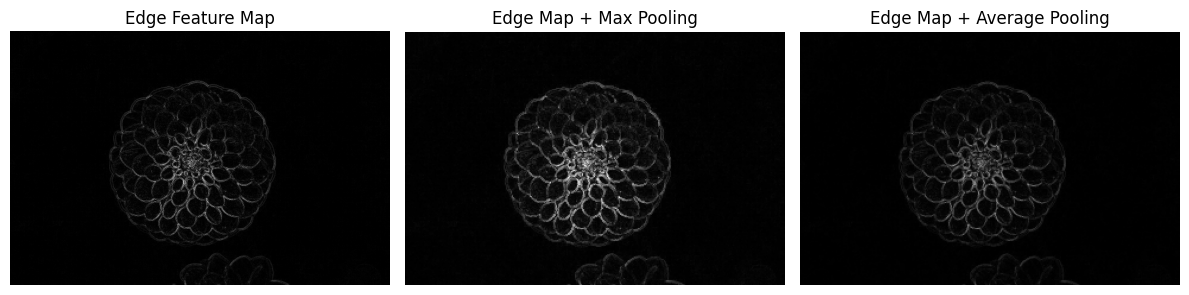

In [6]:
edge_strength = np.abs(edge_result)
edge_strength = edge_strength / (edge_strength.max() + 1e-8)

edge_max_pooled = pool_2x2(edge_strength, mode="max")
edge_avg_pooled = pool_2x2(edge_strength, mode="average")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(edge_strength, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Edge Feature Map")

axes[1].imshow(edge_max_pooled, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Edge Map + Max Pooling")

axes[2].imshow(edge_avg_pooled, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Edge Map + Average Pooling")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 7. Observations

- **Identity filter:** output looks nearly the same as the grayscale input.
- **Edge detection:** highlights boundaries where pixel intensities change rapidly.
- **Sharpen filter:** makes edges and fine details more prominent; excessive sharpening can amplify noise.
- **Blur filter:** smooths local variations and makes edges less distinct.
- **Max pooling:** reduces spatial dimensions while keeping the strongest value in each 2 × 2 region.
- **Average pooling:** reduces dimensions by averaging local regions, often producing a smoother representation.

In a real CNN, filters are usually learned from training data. Hand-designed filters are used here to make the operations easy to understand.

## 8. Conclusion

This experiment demonstrated how convolution filters transform an image into feature maps and how pooling reduces spatial dimensions.

Edge detection emphasizes intensity changes, sharpening highlights details, and blurring smooths local variations. Max pooling preserves stronger local activations, while average pooling retains local mean values. These operations are key building blocks in CNNs, helping neural networks extract useful image features and process them more efficiently.